BLOCK 0 — Nhập thư viện

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import time
from math import *


BLOCK 1 — Tải dữ liệu (nodes, edges, question_bank, profiles)

In [ ]:
import pandas as pd

nodes_df = pd.read_csv("nodes.csv")
edges_adv_df = pd.read_csv("edges.csv")
edges_base_df = pd.read_csv("edges_baseline.csv")
question_bank = pd.read_csv("question_bank.csv")
concept_map_df = pd.read_csv("concept_to_chapter_map.csv")

# ---- Tự động tìm cột concept ----
possible_cols = ["node_id", "concept_id", "node", "id"]

concept_col = None
for c in possible_cols:
    if c in nodes_df.columns:
        concept_col = c
        break

if concept_col is None:
    raise ValueError("Không tìm thấy cột concept trong nodes.csv. Hãy kiểm tra file!")

print("Detected concept column in nodes.csv =", concept_col)

# --- tạo Student Profiles ---
student_profiles = pd.DataFrame({
    "Student_Gioi_Deu": nodes_df[concept_col].apply(lambda x: 1200),
    "Student_Yeu_Deu": nodes_df[concept_col].apply(lambda x: 800),
    "Student_Yeu_HamSo": nodes_df[concept_col].apply(lambda x: 800),
}).T

# rename columns -> elo_<concept>
student_profiles.columns = [f"elo_{c}" for c in nodes_df[concept_col]]

student_profiles.head()


Detected concept column in nodes.csv = concept_id


,elo_MenhDeVaTapHop,elo_MenhDe,elo_TapHop,elo_CacPhepToanTrenTapHop,elo_HieuMenhDeVaDieuKienLogic,elo_NhanBietKhaiNiemCoBanVeTapHop,elo_ThucHienPhepToanTrenTapHop,elo_XacDinhTinhDungSaiCuaMenhDe,elo_VanDungPhepToanTapHop,elo_BatPhuongTrinhBacHaiMotAn,...,elo_HamSoVaDoThi,elo_NhanBietDinhNghiaDuocHamSo,elo_HieuKhaiNiemCoBanVeHamSo,elo_NhanBietCacTrungBinhHoc,elo_VanDungHamSoDeGiaiQuyetVaiBaiToan,elo_HamSoBacHai,elo_NhanBietHinhDangCuaDoThiParabol,elo_TimTapGiaTriCuaHamSoBacHai,elo_VeDoThiParabolCuaHamSoBacHai,elo_VanDungHamSoBacHaiDeGiaiBaiToanThucTien
Student_Gioi_Deu,1200,1200,1200,1200,1200,1200,1200,1200,1200,1200,...,1200,1200,1200,1200,1200,1200,1200,1200,1200,1200
Student_Yeu_Deu,800,800,800,800,800,800,800,800,800,800,...,800,800,800,800,800,800,800,800,800,800
Student_Yeu_HamSo,800,800,800,800,800,800,800,800,800,800,...,800,800,800,800,800,800,800,800,800,800


BLOCK 2 — Xây dựng đồ thị khái niệm

In [ ]:
def build_graph_from_edges(edges_df):
    G = nx.DiGraph()
    for _, row in edges_df.iterrows():
        G.add_edge(row['source'], row['target'])
    return G

concept_graph = build_graph_from_edges(edges_adv_df)
concept_graph_baseline = build_graph_from_edges(edges_base_df)


BLOCK 3 — Tính toán K-factor

In [ ]:
def get_k_factor(questions_answered, k_mode="dynamic", base_k=24):
    if k_mode == "constant":
        return base_k

    if questions_answered < 5:
        return 40
    elif questions_answered < 15:
        return 24
    else:
        return 16


BLOCK 4 — Ánh xạ khái niệm sang chương & xác định cạnh liên chương

In [ ]:
CONCEPT_TO_CHAPTER = dict(zip(concept_map_df['concept_id'], concept_map_df['chapter']))

def build_cross_chapter_info(edges_df, concept_to_chapter):
    cross_edges = set()
    successors = {}

    for _, row in edges_df.iterrows():
        u, v = row['source'], row['target']
        cu, cv = concept_to_chapter.get(u), concept_to_chapter.get(v)
        if cu and cv and cu != cv:
            cross_edges.add((u,v))
        successors.setdefault(u, set()).add(v)

    return cross_edges, successors

CROSS_EDGES_ADV, SUCCESSORS_ADV = build_cross_chapter_info(edges_adv_df, CONCEPT_TO_CHAPTER)
CROSS_EDGES_BASE, SUCCESSORS_BASE = build_cross_chapter_info(edges_base_df, CONCEPT_TO_CHAPTER)


BLOCK 5 —  Thuật toán chọn câu hỏi thích ứng

In [ ]:
def select_adaptive_question(
    student_id,
    student_profiles_df,
    question_bank_df,
    graph,
    concept_to_chapter,
    mastery_threshold=1300.0,
    selection_strategy="lowest_elo",
    prev_ready_nodes=None,
    cross_edges=None,
):
    if cross_edges is None:
        cross_edges = set()

    student_elos = student_profiles_df.loc[student_id]

    # === READY NODES ===
    ready_nodes = []
    for node in graph.nodes():
        elo_col = f'elo_{node}'
        if elo_col not in student_elos:
            continue
        if pd.isna(student_elos[elo_col]):
            continue
        if student_elos[elo_col] >= mastery_threshold:
            continue

        prereqs = list(graph.predecessors(node))
        if not prereqs:
            ready_nodes.append(node)
        else:
            if all(student_elos[f'elo_{p}'] >= mastery_threshold for p in prereqs):
                ready_nodes.append(node)

    # fallback
    if not ready_nodes:
        unmastered = [n for n in graph.nodes()
                      if student_elos.get(f'elo_{n}', -1e9) < mastery_threshold]
        if not unmastered:
            return None, {
                "ready_set_size": 0,
                "newly_unlocked_size": 0,
                "selection_reason": "all_mastered",
                "target_concept": None
            }
        ready_nodes = unmastered

    ready_set_size = len(ready_nodes)
    if prev_ready_nodes is None:
        prev_ready_nodes = set()
    newly_unlocked = set(ready_nodes) - set(prev_ready_nodes)
    newly_unlocked_size = len(newly_unlocked)

    # === STRATEGY ===
    if selection_strategy == "lowest_elo":
        target_concept = min(ready_nodes, key=lambda n: student_elos[f'elo_{n}'])
        selection_reason = "lowest_elo"

    elif selection_strategy == "cross_chapter_unlock":
        cc_candidates = []
        for node in newly_unlocked:
            prereqs = list(graph.predecessors(node))
            for p in prereqs:
                if (p, node) in cross_edges and student_elos[f'elo_{p}'] >= mastery_threshold:
                    cc_candidates.append(node)
                    break

        if cc_candidates:
            target_concept = min(cc_candidates, key=lambda n: student_elos[f'elo_{n}'])
            selection_reason = "new_cross_chapter"
        else:
            target_concept = min(ready_nodes, key=lambda n: student_elos[f'elo_{n}'])
            selection_reason = "lowest_elo_fallback"

    else:
        target_concept = min(ready_nodes, key=lambda n: student_elos[f'elo_{n}'])
        selection_reason = f"fallback_{selection_strategy}"

    # === LẤY CÂU HỎI ===
    qs = question_bank_df[question_bank_df['concept_id'] == target_concept]
    if qs.empty:
        return "RETRY", {
            "ready_set_size": ready_set_size,
            "newly_unlocked_size": newly_unlocked_size,
            "selection_reason": "no_question",
            "target_concept": target_concept
        }

    s_elo = student_elos[f'elo_{target_concept}']
    diff = (qs['elo_difficulty'] - s_elo).abs()
    best_idx = diff.idxmin()
    chosen = qs.loc[best_idx]

    return chosen, {
        "ready_set_size": ready_set_size,
        "newly_unlocked_size": newly_unlocked_size,
        "selection_reason": selection_reason,
        "target_concept": target_concept,
        "ready_nodes": ready_nodes,
    }


BLOCK 6 — Chạy mô phỏng thích ứng cho một học sinh

In [ ]:
def run_adaptive_simulation(
    student_id,
    num_questions,
    student_profiles_df,
    question_bank_df,
    graph,
    concept_to_chapter,
    mastery_threshold=1300.0,
    k_mode="dynamic",
    base_k=24,
    selection_strategy="lowest_elo",
    cross_edges=None,
    engine_type="Advanced"
):
    print(f"\n--- Running {student_id} ({engine_type}) ---")

    student_profiles = student_profiles_df.copy()
    logs = []
    np.random.seed((int(time.time()) + hash(student_id)) % (2**32))

    # đếm số câu đã hỏi trên từng concept để tính K
    concept_counts = {node: 0 for node in graph.nodes()}
    prev_ready_nodes = None
    prev_chapter = None

    for step in range(1, num_questions+1):
        chosen, extra = select_adaptive_question(
            student_id=student_id,
            student_profiles_df=student_profiles,
            question_bank_df=question_bank_df,
            graph=graph,
            concept_to_chapter=concept_to_chapter,
            mastery_threshold=mastery_threshold,
            selection_strategy=selection_strategy,
            prev_ready_nodes=prev_ready_nodes,
            cross_edges=cross_edges,
        )

        # case 1: học sinh đã master hết → dừng
        if chosen is None:
            logs.append({
                "student_id": student_id,
                "engine_type": engine_type,
                "step": step,
                "event": "all_mastered"
            })
            break

        # case 2: select_adaptive_question trả về "RETRY"
        # (string) → bỏ qua step này, không update ELO
        if isinstance(chosen, str) and chosen == "RETRY":
            logs.append({
                "student_id": student_id,
                "engine_type": engine_type,
                "step": step,
                "event": "retry"
            })
            continue

        # từ đây trở xuống: chắc chắn chosen là 1 dòng của question_bank (pd.Series)
        cid = chosen['concept_id']
        qid = chosen['question_id']
        q_elo = float(chosen['elo_difficulty'])

        # ELO trước khi làm câu này
        s_elo_before = float(student_profiles.loc[student_id, f'elo_{cid}'])

        # K-factor theo số câu đã làm trên concept
        k_factor = get_k_factor(
            questions_answered=concept_counts.get(cid, 0),
            k_mode=k_mode,
            base_k=base_k,
        )

        # Xác suất đúng theo logistic Elo
        expected_p = 1 / (1 + 10 ** ((q_elo - s_elo_before) / 400))

        # simulate kết quả: correct = 1 / 0
        correct = 1 if np.random.random() < expected_p else 0

        # update ELO
        s_elo_after = s_elo_before + k_factor * (correct - expected_p)
        student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
        concept_counts[cid] = concept_counts.get(cid, 0) + 1

        # thông tin chương & chuyển chương
        chapter = concept_to_chapter.get(cid, "Unknown")
        if prev_chapter is None:
            chapter_switch = 0
        else:
            chapter_switch = int(chapter != prev_chapter)
        prev_chapter = chapter

        # log step
        logs.append({
            "student_id": student_id,
            "engine_type": engine_type,
            "step": step,
            "question_id": qid,
            "concept_id": cid,
            "chapter": chapter,
            "student_elo_before": round(s_elo_before, 1),
            "question_difficulty": q_elo,
            "expected_p": round(expected_p, 2),
            "is_correct": correct,
            "k_factor_used": k_factor,
            "student_elo_after": round(s_elo_after, 1),
            "selection_reason": extra.get("selection_reason"),
            "ready_set_size": extra.get("ready_set_size"),
            "newly_unlocked_size": extra.get("newly_unlocked_size"),
            "chapter_switch_flag": chapter_switch,
        })

        # cập nhật tập ready_nodes cho lần sau
        prev_ready_nodes = set(extra.get("ready_nodes", []))

    return pd.DataFrame(logs), student_profiles


BLOCK 7 — Chạy mô phỏng cho tất cả học sinh (một engine)

In [ ]:
def run_one_engine_all_students(
    engine_type,
    graph,
    cross_edges,
    mastery_threshold,
    k_mode,
    base_k,
    selection_strategy,
    num_questions=500
):
    profiles = student_profiles.copy()
    logs = []

    for stu in profiles.index:
        log_df, profiles = run_adaptive_simulation(
            stu, num_questions, profiles, question_bank,
            graph, CONCEPT_TO_CHAPTER,
            mastery_threshold=mastery_threshold,
            k_mode=k_mode,
            base_k=base_k,
            selection_strategy=selection_strategy,
            cross_edges=cross_edges,
            engine_type=engine_type
        )
        logs.append(log_df)

    if logs:
        return pd.concat(logs, ignore_index=True), profiles
    return pd.DataFrame(), profiles


BLOCK 8 — Tổng hợp kết quả thí nghiệm

In [ ]:
def summarize_experiment(log_df, engine_type, mastery_threshold, k_mode, base_k, selection_strategy):
    if log_df.empty:
        return []

    res = []
    for stu, g in log_df.groupby("student_id"):
        res.append({
            "engine_type": engine_type,
            "student_id": stu,
            "mastery_threshold": mastery_threshold,
            "k_mode": k_mode,
            "base_k": base_k,
            "selection_reason": selection_strategy,
            "total_questions": len(g),
            "chapter_switches": int(g["chapter_switch_flag"].sum()),
            "avg_ready_size": round(g["ready_set_size"].mean(),2)
        })
    return res


BLOCK 9 —  Tự động hóa phân tích độ nhạy (sensitivity grid)

In [ ]:
def run_sensitivity_grid():
    mastery_thresholds = [1250, 1300, 1350]
    k_modes = ["constant", "dynamic"]
    base_ks = [16, 24, 32]
    strategies = ["lowest_elo", "cross_chapter_unlock"]

    all_res = []

    for mt in mastery_thresholds:
        for km in k_modes:
            for bk in base_ks:
                for strat in strategies:

                    print(f"\n=== ADVANCED: mt={mt}, k={km}, base={bk}, strat={strat} ===")
                    adv_log, _ = run_one_engine_all_students(
                        "Advanced", concept_graph, CROSS_EDGES_ADV,
                        mt, km, bk, strat
                    )
                    all_res.extend(
                        summarize_experiment(adv_log, "Advanced", mt, km, bk, strat)
                    )

                    print(f"\n=== BASELINE: mt={mt}, k={km}, base={bk}, strat={strat} ===")
                    base_log, _ = run_one_engine_all_students(
                        "Baseline", concept_graph_baseline, CROSS_EDGES_BASE,
                        mt, km, bk, strat
                    )
                    all_res.extend(
                        summarize_experiment(base_log, "Baseline", mt, km, bk, strat)
                    )

    df = pd.DataFrame(all_res)
    df.to_csv("sensitivity_summary.csv", index=False)
    return df


BLOCK 10 — Chạy toàn bộ phân tích độ nhạy

In [ ]:
sensitivity_df = run_sensitivity_grid()
sensitivity_df.head()



=== ADVANCED: mt=1250, k=constant, base=16, strat=lowest_elo ===

--- Running Student_Gioi_Deu (Advanced) ---


/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1200.1841742594847' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1184.1841742594847' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1215.8158257405153' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_afte


--- Running Student_Yeu_Deu (Advanced) ---

--- Running Student_Yeu_HamSo (Advanced) ---

=== BASELINE: mt=1250, k=constant, base=16, strat=lowest_elo ===

--- Running Student_Gioi_Deu (Baseline) ---


/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1200.1841742594847' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1199.8158257405153' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1215.8158257405153' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_afte


--- Running Student_Yeu_Deu (Baseline) ---

--- Running Student_Yeu_HamSo (Baseline) ---

=== ADVANCED: mt=1250, k=constant, base=16, strat=cross_chapter_unlock ===

--- Running Student_Gioi_Deu (Advanced) ---

--- Running Student_Yeu_Deu (Advanced) ---


/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1200.1841742594847' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1200.1841742594847' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '796.9330827607913' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after

... (146 outputs left out)


--- Running Student_Yeu_HamSo (Advanced) ---

=== BASELINE: mt=1350, k=dynamic, base=32, strat=cross_chapter_unlock ===

--- Running Student_Gioi_Deu (Baseline) ---


/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1201.1500225556908' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1161.1500225556908' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_after
/tmp/ipython-input-18807779.py:83: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1201.1500225556908' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  student_profiles.loc[student_id, f'elo_{cid}'] = s_elo_afte


--- Running Student_Yeu_Deu (Baseline) ---

--- Running Student_Yeu_HamSo (Baseline) ---


,engine_type,student_id,mastery_threshold,k_mode,base_k,selection_reason,total_questions,chapter_switches,avg_ready_size
0,Advanced,Student_Gioi_Deu,1250,constant,16,lowest_elo,500,11,3.0
1,Advanced,Student_Yeu_Deu,1250,constant,16,lowest_elo,500,7,3.0
2,Advanced,Student_Yeu_HamSo,1250,constant,16,lowest_elo,500,3,3.0
3,Baseline,Student_Gioi_Deu,1250,constant,16,lowest_elo,500,11,3.0
4,Baseline,Student_Yeu_Deu,1250,constant,16,lowest_elo,500,14,3.0


BLOCK 11 — Biểu đồ: So sánh Advanced vs Baseline (lowest_elo)


<Figure size 1000x600 with 0 Axes>

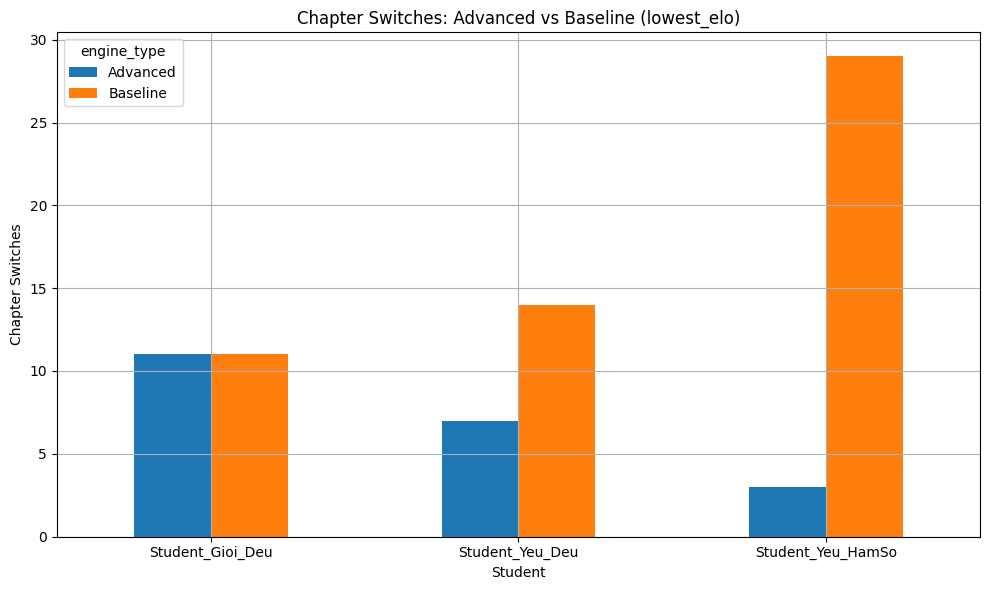

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sensitivity_summary.csv")

subset = df[
    (df['selection_reason'] == 'lowest_elo') &
    (df['base_k'] == 16) &
    (df['k_mode'] == 'constant') &
    (df['mastery_threshold'] == 1250)
]

pivot = subset.pivot(index='student_id', columns='engine_type', values='chapter_switches')

plt.figure(figsize=(10,6))
pivot.plot(kind='bar')
plt.title("Chapter Switches: Advanced vs Baseline (lowest_elo)")
plt.xlabel("Student")
plt.ylabel("Chapter Switches")
plt.xticks(rotation=0)
plt.grid(True)
plt.tight_layout()
plt.show()

BLOCK 12 — Biểu đồ: So sánh chiến lược (lowest_elo vs cross_chapter_unlock)

<Figure size 1000x600 with 0 Axes>

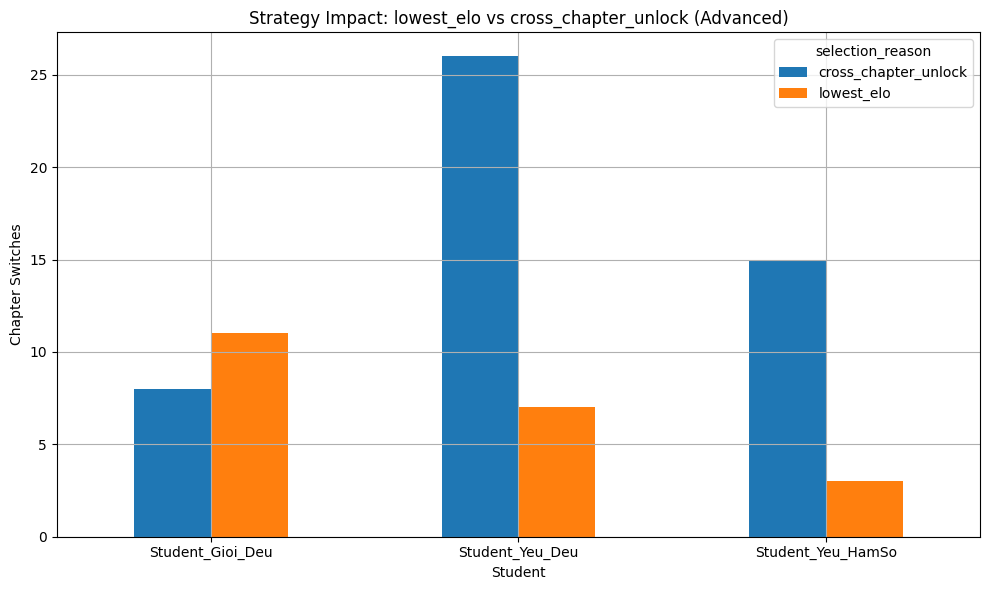

In [ ]:
subset2 = df[
    (df['engine_type'] == 'Advanced') &
    (df['base_k'] == 16) &
    (df['k_mode'] == 'constant') &
    (df['mastery_threshold'] == 1250)
]

pivot2 = subset2.pivot(index='student_id', columns='selection_reason', values='chapter_switches')

plt.figure(figsize=(10,6))
pivot2.plot(kind='bar')
plt.title("Strategy Impact: lowest_elo vs cross_chapter_unlock (Advanced)")
plt.xlabel("Student")
plt.ylabel("Chapter Switches")
plt.xticks(rotation=0)
plt.grid(True)
plt.tight_layout()
plt.show()

BLOCK 13 — Biểu đồ: Ảnh hưởng của base_k lên số lần chuyển chương

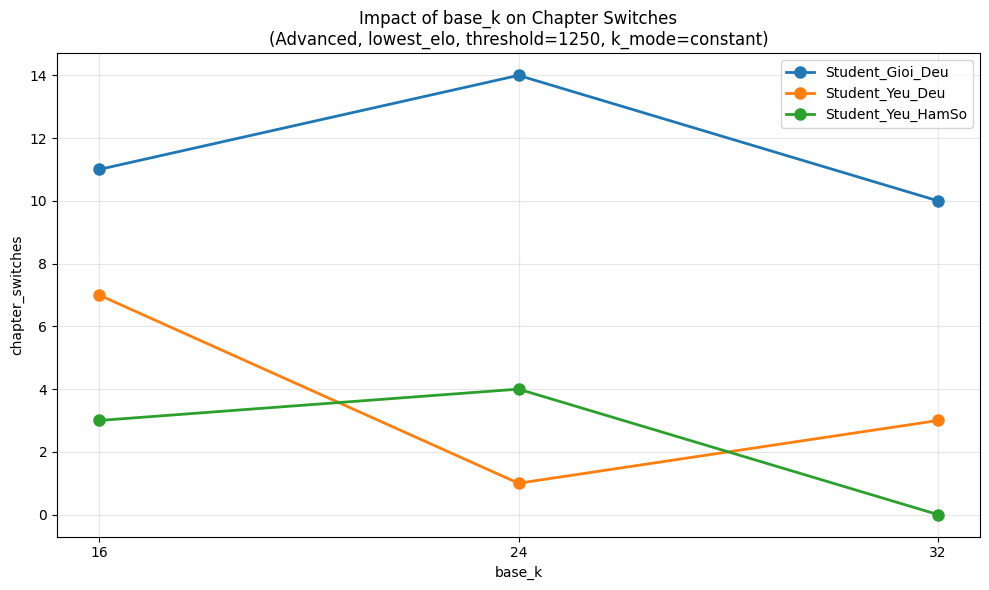

In [ ]:
# === BLOCK 13A: Impact of base_k on Chapter Switches (k_mode = constant) ===

subset3_const = df[
    (df['engine_type'] == 'Advanced') &
    (df['selection_reason'] == 'lowest_elo') &
    (df['mastery_threshold'] == 1250) &
    (df['k_mode'] == 'constant')
].copy()

plt.figure(figsize=(10,6))
for stu in subset3_const['student_id'].unique():
    d = subset3_const[subset3_const['student_id'] == stu].sort_values("base_k")
    plt.plot(
        d['base_k'],
        d['chapter_switches'],
        marker='o',
        markersize=8,
        linewidth=2,
        label=stu
    )

plt.title("Impact of base_k on Chapter Switches\n(Advanced, lowest_elo, threshold=1250, k_mode=constant)")
plt.xlabel("base_k")
plt.ylabel("chapter_switches")
plt.xticks(sorted(subset3_const['base_k'].unique()))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


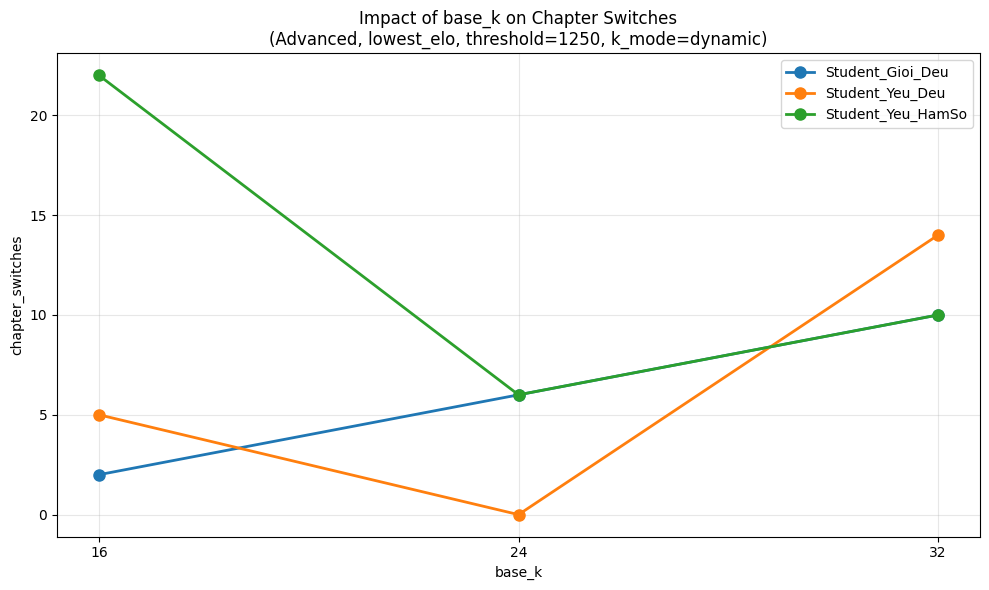

In [ ]:
# === BLOCK 13B: Impact of base_k on Chapter Switches (k_mode = dynamic) ===

subset3_dyn = df[
    (df['engine_type'] == 'Advanced') &
    (df['selection_reason'] == 'lowest_elo') &
    (df['mastery_threshold'] == 1250) &
    (df['k_mode'] == 'dynamic')
].copy()

plt.figure(figsize=(10,6))
for stu in subset3_dyn['student_id'].unique():
    d = subset3_dyn[subset3_dyn['student_id'] == stu].sort_values("base_k")
    plt.plot(
        d['base_k'],
        d['chapter_switches'],
        marker='o',
        markersize=8,
        linewidth=2,
        label=stu
    )

plt.title("Impact of base_k on Chapter Switches\n(Advanced, lowest_elo, threshold=1250, k_mode=dynamic)")
plt.xlabel("base_k")
plt.ylabel("chapter_switches")
plt.xticks(sorted(subset3_dyn['base_k'].unique()))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


BLOCK 14 — Biểu đồ: Ảnh hưởng của mastery_threshold lên số lần chuyển chương

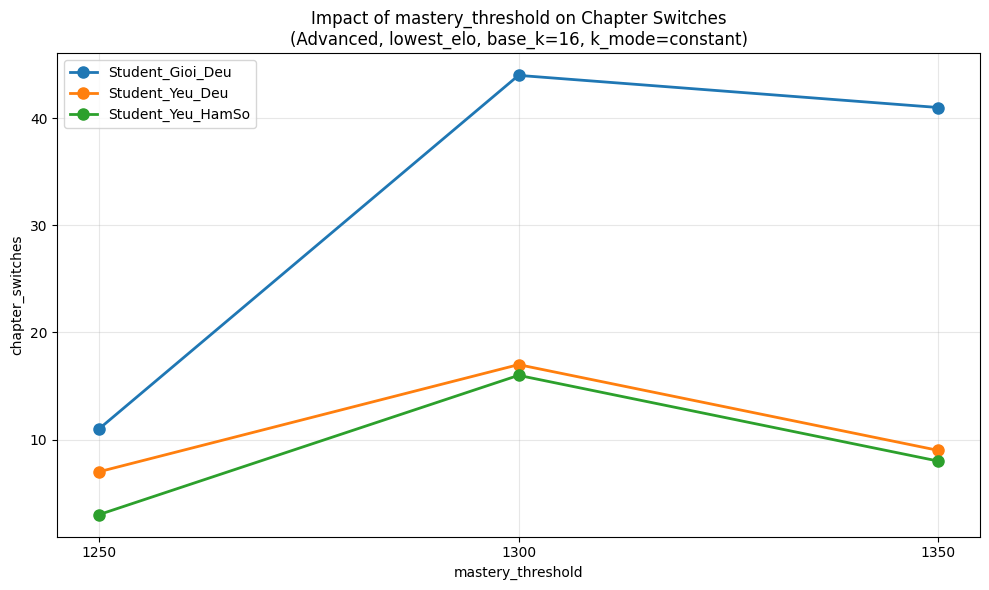

In [ ]:
# === BLOCK 14A: Impact of mastery_threshold on Chapter Switches (k_mode = constant) ===

subset4_const = df[
    (df['engine_type'] == 'Advanced') &
    (df['selection_reason'] == 'lowest_elo') &
    (df['base_k'] == 16) &
    (df['k_mode'] == 'constant')
].copy()

plt.figure(figsize=(10,6))

for stu in subset4_const['student_id'].unique():
    d = subset4_const[subset4_const['student_id'] == stu].sort_values("mastery_threshold")
    plt.plot(
        d['mastery_threshold'],
        d['chapter_switches'],
        marker='o',
        markersize=8,
        linewidth=2,
        label=stu
    )

plt.title("Impact of mastery_threshold on Chapter Switches\n(Advanced, lowest_elo, base_k=16, k_mode=constant)")
plt.xlabel("mastery_threshold")
plt.ylabel("chapter_switches")
plt.xticks(sorted(subset4_const['mastery_threshold'].unique()))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


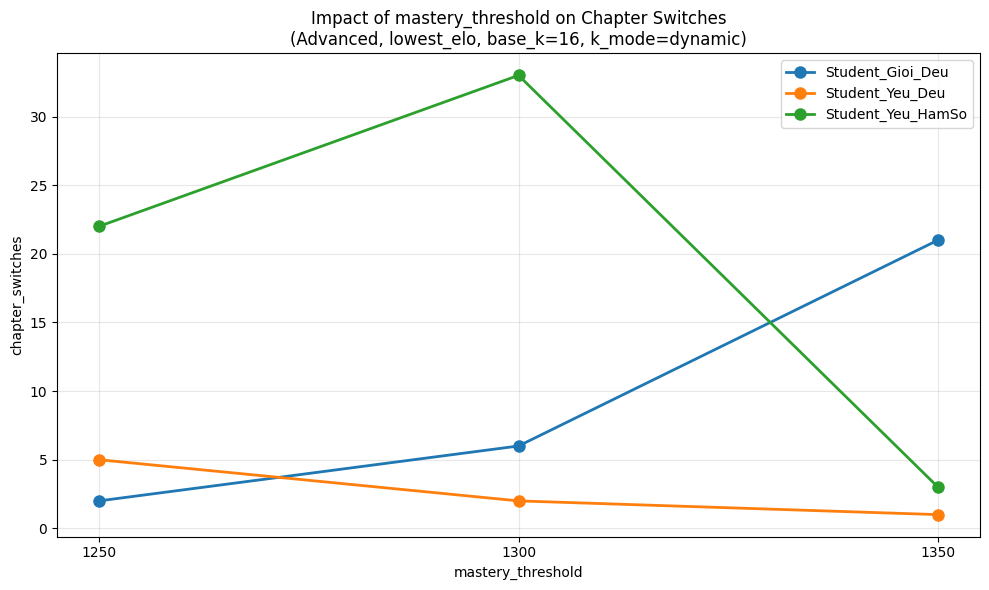

In [ ]:
# === BLOCK 14B: Impact of mastery_threshold on Chapter Switches (k_mode = dynamic) ===

subset4_dyn = df[
    (df['engine_type'] == 'Advanced') &
    (df['selection_reason'] == 'lowest_elo') &
    (df['base_k'] == 16) &
    (df['k_mode'] == 'dynamic')
].copy()

plt.figure(figsize=(10,6))

for stu in subset4_dyn['student_id'].unique():
    d = subset4_dyn[subset4_dyn['student_id'] == stu].sort_values("mastery_threshold")
    plt.plot(
        d['mastery_threshold'],
        d['chapter_switches'],
        marker='o',
        markersize=8,
        linewidth=2,
        label=stu
    )

plt.title("Impact of mastery_threshold on Chapter Switches\n(Advanced, lowest_elo, base_k=16, k_mode=dynamic)")
plt.xlabel("mastery_threshold")
plt.ylabel("chapter_switches")
plt.xticks(sorted(subset4_dyn['mastery_threshold'].unique()))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


BLOCK 15 — Biểu đồ: Phân phối kích thước tập ready theo chiến lược

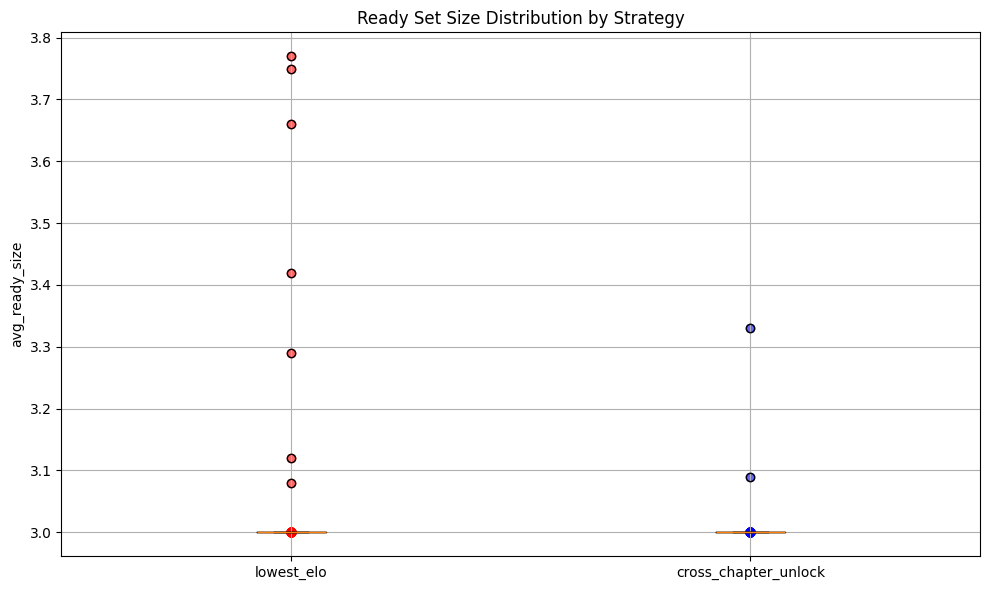

In [ ]:
data_low = df[df['selection_reason']=='lowest_elo']['avg_ready_size']
data_unlock = df[df['selection_reason']=='cross_chapter_unlock']['avg_ready_size']

plt.figure(figsize=(10,6))

plt.boxplot([data_low, data_unlock],
            tick_labels=['lowest_elo', 'cross_chapter_unlock'])

# add scatter to show actual points
plt.scatter([1]*len(data_low), data_low, color='red', alpha=0.6)
plt.scatter([2]*len(data_unlock), data_unlock, color='blue', alpha=0.6)

plt.title("Ready Set Size Distribution by Strategy")
plt.ylabel("avg_ready_size")
plt.grid(True)
plt.tight_layout()
plt.show()
